# 10 - Refining the tier probabilities (after the final test)

Feedback on the cards: from about pick 10 on, the bottom tier looked too likely.
Two things were checked:

1. **Calibration by pick:** the original probabilities were a bit pessimistic for
   picks 11-30 (predicted ~60% bottom tier vs ~55% real) and optimistic for picks
   46-60 (71% vs 87%). Cause: a mid-first-rounder projected at ~1 VORP was compared
   with *everyone* projected at ~1, including many second-rounders, who fail more.
2. **The bottom tier's name:** "Little or no value" read as "bust", but a third of
   those players played 1,000+ minutes in years 3-4 (Dillon Brooks, Evan Turner...).
   It is renamed **"Replacement level"**, which is what VORP < 0.5 means.

The fix for (1): neighbours must be similar in projection **and** in draft
position (distance in log(pick)). How strongly the pick counts is chosen on the
development set by Brier score, like the other settings in 05.

**This change is made after the final test**, so it is recorded as such. The test
classes are only looked at at the end, as a check, not to choose anything.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
import projection as pj
from plot_style import apply_style, BLUE, ORANGE, NEUTRAL, INK_2

apply_style()
df = md.add_pick_terms(m.load_table())
dev = m.dev_set(df).set_index("player_id", drop=False)
_, oof = m.repeated_cv(md.ensemble, md.ALL, dev.reset_index(drop=True))
dev["model_pred"] = oof.to_numpy()
truth = dev[m.TARGET]
KERNEL = dict(bandwidth=0.5, min_neighbors=50)
BOTTOM, TOP2 = pj.TIER_NAMES[0], pj.TIER_NAMES[3:]
print(f"Development set: {len(dev)} players. Bottom tier is now called '{BOTTOM}'.")

Development set: 683 players. Bottom tier is now called 'Replacement level'.


## 1. How much should the pick count?

`pick_bandwidth` is in log(pick) units: 0.5 means picks ~1.6x apart (e.g. 10 and 16)
are "one step" away. Smaller = the pick matters more. `None` = the original method.

In [2]:
def probs_for(pick_bw):
    extra = {} if pick_bw is None else dict(picks=dev["pick"], ref_picks=dev["pick"], pick_bandwidth=pick_bw)
    return pj.tier_probabilities(dev["model_pred"], dev["model_pred"], truth,
                                 exclude_self=True, **KERNEL, **extra)

grid = [None, 0.25, 0.5, 0.75, 1.0, 1.5]
probs = {bw: probs_for(bw) for bw in grid}
brier = pd.Series({("original (no pick)" if bw is None else bw): pj.brier_score(p, truth)
                   for bw, p in probs.items()}, name="Brier (lower is better)")
PICK_BW = min((bw for bw in grid if bw is not None), key=lambda bw: pj.brier_score(probs[bw], truth))
print(f"Chosen pick bandwidth: {PICK_BW}")
brier.round(4)

Chosen pick bandwidth: 0.5


original (no pick)    0.5322
0.25                  0.5323
0.5                   0.5301
0.75                  0.5307
1.0                   0.5316
1.5                   0.5309
Name: Brier (lower is better), dtype: float64

## 2. Calibration by pick range (development set)

In [3]:
BUCKETS = [0, 5, 10, 20, 30, 45, 60]
LABELS = ["1-5", "6-10", "11-20", "21-30", "31-45", "46-60"]


def calibration(frame, p_orig, p_new, truth_s):
    b = pd.cut(frame["pick"], BUCKETS, labels=LABELS)
    real = pj.tier_of(truth_s)
    out = pd.DataFrame({
        "players": b.value_counts().reindex(LABELS),
        f"{BOTTOM}: original": p_orig[BOTTOM].groupby(b, observed=True).mean(),
        f"{BOTTOM}: with pick": p_new[BOTTOM].groupby(b, observed=True).mean(),
        f"{BOTTOM}: real": (real == BOTTOM).groupby(b, observed=True).mean(),
        "starter+: original": p_orig[TOP2].sum(axis=1).groupby(b, observed=True).mean(),
        "starter+: with pick": p_new[TOP2].sum(axis=1).groupby(b, observed=True).mean(),
        "starter+: real": real.isin(TOP2).groupby(b, observed=True).mean(),
    })
    return out


cal_dev = calibration(dev, probs[None], probs[PICK_BW], truth)
cal_dev.round(2)

,players,Replacement level: original,Replacement level: with pick,Replacement level: real,starter+: original,starter+: with pick,starter+: real
pick,,,,,,,
1-5,70,0.33,0.32,0.29,0.29,0.30,0.36
6-10,69,0.48,0.44,0.43,0.17,0.17,0.22
11-20,138,0.60,0.56,0.55,0.08,0.08,0.07
21-30,135,0.63,0.62,0.54,0.07,0.06,0.10
31-45,168,0.69,0.72,0.71,0.05,0.04,0.03
46-60,103,0.71,0.77,0.85,0.04,0.03,0.03


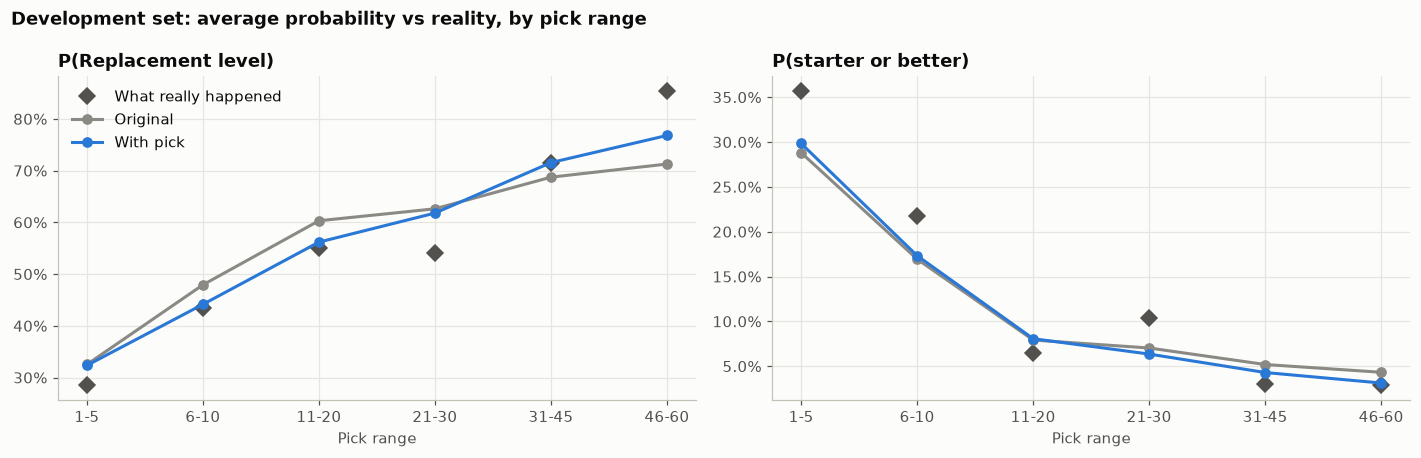

In [4]:
def plot_cal(cal, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
    x = np.arange(len(cal))
    for ax, prefix, name in [(axes[0], BOTTOM, f"P({BOTTOM})"), (axes[1], "starter+", "P(starter or better)")]:
        ax.plot(x, cal[f"{prefix}: real"], color=INK_2, marker="D", markersize=7, linewidth=0, label="What really happened")
        ax.plot(x, cal[f"{prefix}: original"], color=NEUTRAL, marker="o", label="Original")
        ax.plot(x, cal[f"{prefix}: with pick"], color=BLUE, marker="o", label="With pick")
        ax.set_xticks(x, cal.index)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
        ax.set(title=name, xlabel="Pick range")
    axes[0].legend(loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_cal(cal_dev, "Development set: average probability vs reality, by pick range")

**What to look for:** the blue line should sit closer to the diamonds than the grey
one, especially at picks 11-30 (where the original was too pessimistic) and 46-60
(where it was too optimistic).

## 3. Check on the test classes (after the fact)

Walk-forward predictions exactly as in 08; development set as reference. Nothing
here is used to choose anything.

Test Brier - original: 0.5101 | with pick: 0.5080


,players,Replacement level: original,Replacement level: with pick,Replacement level: real,starter+: original,starter+: with pick,starter+: real
pick,,,,,,,
1-5,29,0.30,0.30,0.28,0.33,0.34,0.34
6-10,30,0.46,0.42,0.43,0.17,0.17,0.13
11-20,60,0.54,0.51,0.53,0.11,0.11,0.12
21-30,60,0.61,0.60,0.57,0.07,0.07,0.05
31-45,83,0.66,0.70,0.71,0.05,0.04,0.00
46-60,69,0.71,0.77,0.87,0.04,0.03,0.00


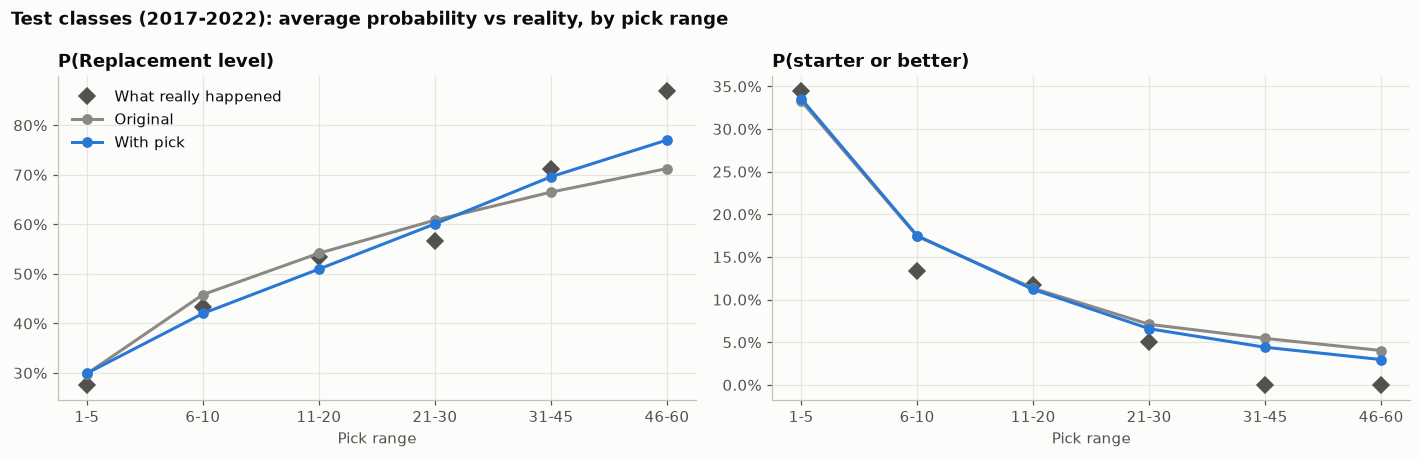

In [5]:
wf = m.walk_forward(md.ensemble, md.ALL, df).set_index("player_id")
ref_kw = dict(picks=wf["pick"], ref_picks=dev["pick"], pick_bandwidth=PICK_BW)
t_orig = pj.tier_probabilities(wf["pred"], dev["model_pred"], truth, **KERNEL)
t_new = pj.tier_probabilities(wf["pred"], dev["model_pred"], truth, **KERNEL, **ref_kw)
print(f"Test Brier - original: {pj.brier_score(t_orig, wf[m.TARGET]):.4f} | "
      f"with pick: {pj.brier_score(t_new, wf[m.TARGET]):.4f}")
cal_test = calibration(wf, t_orig, t_new, wf[m.TARGET])
display(cal_test.round(2))
plot_cal(cal_test, "Test classes (2017-2022): average probability vs reality, by pick range")

## Decision

The cards from now on use the pick-aware probabilities (`pick_bandwidth` chosen
above) and the new name for the bottom tier. Notebooks 05 and 08 keep the original
method, so their recorded results stay reproducible.